# Clasificación de la demanda de urgencias con un árbol de decisión

Objetivo: clasificar una atención como urgente (triaje 1, 2 o 3) o no urgente (triaje 4 o 5) con un árbol de decisión, usando solo la edad, la hora, el sexo y el día de la semana.

El escenario del curso es el servicio de urgencias del Hospital Obrero N.º 1. Los registros de este cuaderno no son de ese hospital. Son triajes de 14 hospitales de Castilla y León. Los resultados no describen a los pacientes del Hospital Obrero.

Es un ejercicio experimental de clasificación. No es una herramienta clínica validada. El modelo no decide qué pacientes reciben atención urgente.


## 1. Definición del problema y de la variable objetivo

En urgencias, parte de las llegadas queda en triaje 4 o 5. El trabajo plantea, como escenario, si esa demanda de baja complejidad se puede separar de la urgente (triaje 1, 2 o 3) para estudiar una vía rápida. Eso es el contexto del ejercicio. No es un protocolo del hospital.

La variable dependiente es `objetivo`:

- **0, urgente:** triaje 1, 2 o 3.
- **1, no urgente:** triaje 4 o 5.

Uso dos clases porque la pregunta del ejercicio también es de dos clases: grupo urgente o grupo no urgente. La etiqueta ya viene del triaje registrado. El modelo no diagnostica y no reemplaza esa clasificación.

Las independientes son cuatro datos de la llegada:

- **Edad.**
- **Hora**, pasada a un entero de 0 a 23.
- **Sexo.**
- **Día de la semana.**

No uso zona básica, ámbito, hospital, área ni provincia. El hospital indicaría el centro donde ya se atendió a la persona, y aquí hay 14 centros. El archivo tampoco trae síntomas ni signos vitales. Con estas cuatro variables solo se puede ver si el perfil de llegada se parece al triaje ya registrado.


## 2. Preparación de los datos

El nombre del archivo en el proyecto es `urgencias-hospitalarias-atendidas-20252026`. No estaba el Excel en el repositorio de partida. Ese nombre es el del conjunto abierto «Urgencias Hospitalarias atendidas - 2025/2026» de la Junta de Castilla y León (licencia CC BY 4.0). Las columnas son las once del proyecto: fecha, día, hora, nivel de triaje, zona básica, ámbito, hospital, área, provincia, edad y sexo.

El cuaderno lee `data/urgencias-hospitalarias-atendidas-20252026.parquet`, con el directorio de trabajo en la carpeta del notebook. Si el archivo no está, lo descarga del portal público. El enlace queda en el código.

El proyecto citó un corte de 1.001.766 filas. El portal actualiza los datos, así que al ejecutar puede haber más filas. Siguen siendo los 14 hospitales de Castilla y León. No son registros del Hospital Obrero N.º 1 y no invento filas para simular ese centro.

Limpieza, en este orden:

- Dejo triajes 1, 2, 3, 4 y 5. «Desconocido» y cualquier otro texto se descartan.
- La edad fuera de 0 a 120 pasa a nulo. La mediana se calcula solo con el entrenamiento y después se aplica a la prueba.
- La hora pasa de `HH:MM` a un entero de 0 a 23. Si alguna fila no se puede leer, también se rellena con la mediana del entrenamiento.
- Sexo y día vacíos quedan como `Desconocido`.
- Sexo y día pasan a variables indicadoras, sin quitar una categoría. En un árbol no hace falta una categoría de referencia.
- La partición es 80 % entrenamiento y 20 % prueba, estratificada, con `random_state=42`. El árbol se ajusta con 64.000 filas estratificadas de ese entrenamiento. La prueba se evalúa completa.


In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    make_scorer,
    ConfusionMatrixDisplay,
)

URL_PARQUET = (
    "https://analisis.datosabiertos.jcyl.es/api/explore/v2.1/catalog/datasets/"
    "urgencias-hospitalarias-atendidas-20252026/exports/parquet"
)
FICHA = (
    "https://analisis.datosabiertos.jcyl.es/explore/dataset/"
    "urgencias-hospitalarias-atendidas-20252026/"
)
ARCHIVO_DATOS = Path("data/urgencias-hospitalarias-atendidas-20252026.parquet")

if not ARCHIVO_DATOS.exists() or ARCHIVO_DATOS.stat().st_size < 1_000_000:
    print("No está data/urgencias-hospitalarias-atendidas-20252026.parquet. Descargando la exportación pública...")
    ARCHIVO_DATOS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_PARQUET, ARCHIVO_DATOS)

crudo = pd.read_parquet(ARCHIVO_DATOS)
columnas_exigidas = [
    "fecha_de_atencion",
    "dia_de_la_semana",
    "hora",
    "nivel_de_triaje",
    "zona_basica_de_salud",
    "ambito_de_procedencia",
    "hospital",
    "area",
    "provincia",
    "edad",
    "sexo",
]
faltan = [c for c in columnas_exigidas if c not in crudo.columns]
if faltan:
    raise RuntimeError(
        "La exportación no trae las columnas del proyecto: " + ", ".join(faltan)
    )

def miles(n):
    return f"{int(n):,}".replace(",", ".")

def porcentaje(x):
    return f"{x * 100:.2f}".replace(".", ",") + " %"

print("Fuente:", FICHA)
print("Archivo:", "data/urgencias-hospitalarias-atendidas-20252026.parquet")
print(f"Filas en el archivo: {miles(len(crudo))}")
print(f"Hospitales distintos en el archivo: {crudo['hospital'].nunique()}")
print("Columnas:", ", ".join(crudo.columns))


Fuente: https://analisis.datosabiertos.jcyl.es/explore/dataset/urgencias-hospitalarias-atendidas-20252026/
Archivo: data/urgencias-hospitalarias-atendidas-20252026.parquet
Filas en el archivo: 1.886.459
Hospitales distintos en el archivo: 14
Columnas: fecha_de_atencion, dia_de_la_semana, hora, nivel_de_triaje, zona_basica_de_salud, ambito_de_procedencia, hospital, area, provincia, edad, sexo


In [2]:
trabajo = crudo.copy()
n_inicial = len(trabajo)

trabajo["triaje"] = pd.to_numeric(trabajo["nivel_de_triaje"], errors="coerce")
trabajo = trabajo[trabajo["triaje"].isin([1, 2, 3, 4, 5])].copy()
trabajo["triaje"] = trabajo["triaje"].astype(int)
descartadas_triaje = n_inicial - len(trabajo)

# 0 = urgente (1-3); 1 = no urgente (4-5). Misma definición que la logística.
trabajo["objetivo"] = trabajo["triaje"].isin([4, 5]).astype(int)

trabajo["edad"] = pd.to_numeric(trabajo["edad"], errors="coerce")
edad_fuera_de_rango = ((trabajo["edad"] < 0) | (trabajo["edad"] > 120)).sum()
trabajo.loc[(trabajo["edad"] < 0) | (trabajo["edad"] > 120), "edad"] = np.nan

hora_texto = trabajo["hora"].astype(str).str.strip()
hora_extraida = hora_texto.str.extract(r"^(\d{1,2})")[0]
trabajo["hora_num"] = pd.to_numeric(hora_extraida, errors="coerce")
fraccion = pd.to_numeric(hora_texto, errors="coerce")
es_fraccion_excel = trabajo["hora_num"].isna() & fraccion.notna() & (fraccion >= 0) & (fraccion < 1)
trabajo.loc[es_fraccion_excel, "hora_num"] = np.floor(fraccion[es_fraccion_excel] * 24)
hora_invalida = (trabajo["hora_num"] < 0) | (trabajo["hora_num"] > 23)
trabajo.loc[hora_invalida, "hora_num"] = np.nan

nulos_edad = int(trabajo["edad"].isna().sum())
nulos_hora = int(trabajo["hora_num"].isna().sum())
nulos_sexo = int(trabajo["sexo"].isna().sum())
nulos_dia = int(trabajo["dia_de_la_semana"].isna().sum())

trabajo["sexo"] = trabajo["sexo"].fillna("Desconocido").astype(str).str.strip()
trabajo["dia"] = trabajo["dia_de_la_semana"].fillna("Desconocido").astype(str).str.strip()
trabajo.loc[trabajo["sexo"].isin(["", "nan", "None"]), "sexo"] = "Desconocido"
trabajo.loc[trabajo["dia"].isin(["", "nan", "None"]), "dia"] = "Desconocido"

predictores = trabajo[["edad", "hora_num", "sexo", "dia"]].copy()
y = trabajo["objetivo"].copy()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    predictores,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

n_ajuste = min(64_000, len(X_train_full))
if n_ajuste < len(X_train_full):
    X_train, _, y_train, _ = train_test_split(
        X_train_full,
        y_train_full,
        train_size=n_ajuste,
        random_state=42,
        stratify=y_train_full,
    )
else:
    X_train = X_train_full
    y_train = y_train_full

mediana_edad = float(X_train["edad"].median())
mediana_hora = float(X_train["hora_num"].median())
X_train = X_train.copy()
X_test = X_test.copy()
X_train["edad"] = X_train["edad"].fillna(mediana_edad)
X_test["edad"] = X_test["edad"].fillna(mediana_edad)
X_train["hora_num"] = X_train["hora_num"].fillna(mediana_hora)
X_test["hora_num"] = X_test["hora_num"].fillna(mediana_hora)
X_train = X_train.rename(columns={"hora_num": "hora"})
X_test = X_test.rename(columns={"hora_num": "hora"})

X_train_dm = pd.get_dummies(X_train, columns=["sexo", "dia"], dtype=float)
X_test_dm = pd.get_dummies(X_test, columns=["sexo", "dia"], dtype=float)
X_test_dm = X_test_dm.reindex(columns=X_train_dm.columns, fill_value=0.0)

print("Limpieza y partición")
print(f"Filas leídas: {miles(n_inicial)}")
print(f"Descartadas por triaje distinto de 1-5: {miles(descartadas_triaje)}")
print(f"Filas válidas para el objetivo: {miles(len(trabajo))}")
print(f"Edades fuera de 0-120, pasadas a nulo: {miles(edad_fuera_de_rango)}")
print(f"Nulos de edad antes de imputar: {miles(nulos_edad)}")
print(f"Nulos de hora antes de imputar: {miles(nulos_hora)}")
print(f"Nulos de sexo, rellenados con Desconocido: {miles(nulos_sexo)}")
print(f"Nulos de día, rellenados con Desconocido: {miles(nulos_dia)}")
print(f"Mediana de edad aprendida en entrenamiento: {mediana_edad:.1f} años")
print(f"Mediana de hora aprendida en entrenamiento: {mediana_hora:.0f}")
print(f"Entrenamiento usado para ajustar el árbol: {miles(len(X_train_dm))} filas")
print(f"Prueba, completa y no usada en el ajuste: {miles(len(X_test_dm))} filas")
print(f"Proporción de clase 1 (no urgente) en prueba: {porcentaje(y_test.mean())}")
print(f"Proporción de clase 0 (urgente) en prueba: {porcentaje(1 - y_test.mean())}")
print("Predictoras codificadas:", ", ".join(X_train_dm.columns))
print()
print(
    "La mediana no se calcula con la prueba. Sexo y día entran como indicadoras, "
    "así el árbol puede elegir un día o un sexo concreto sin una categoría de referencia oculta."
)

Limpieza y partición
Filas leídas: 1.886.459
Descartadas por triaje distinto de 1-5: 83.537
Filas válidas para el objetivo: 1.802.922
Edades fuera de 0-120, pasadas a nulo: 0
Nulos de edad antes de imputar: 1.447
Nulos de hora antes de imputar: 0
Nulos de sexo, rellenados con Desconocido: 1.447
Nulos de día, rellenados con Desconocido: 0
Mediana de edad aprendida en entrenamiento: 52.0 años
Mediana de hora aprendida en entrenamiento: 15
Entrenamiento usado para ajustar el árbol: 64.000 filas
Prueba, completa y no usada en el ajuste: 360.585 filas
Proporción de clase 1 (no urgente) en prueba: 57,67 %
Proporción de clase 0 (urgente) en prueba: 42,33 %
Predictoras codificadas: edad, hora, sexo_Desconocido, sexo_Hombre, sexo_Mujer, dia_DOMINGO, dia_JUEVES, dia_LUNES, dia_MARTES, dia_MIÉRCOLES, dia_SÁBADO, dia_VIERNES

La mediana no se calcula con la prueba. Sexo y día entran como indicadoras, así el árbol puede elegir un día o un sexo concreto sin una categoría de referencia oculta.


La salida deja el tamaño de esta ejecución: filas leídas, filas descartadas por triaje distinto de 1-5, filas válidas, nulos rellenados, mediana de edad y de hora, y el tamaño del ajuste y de la prueba. La clase no urgente es la mayoritaria. Esos conteos son del archivo de Castilla y León, no de una base del Hospital Obrero.


## 3. Entrenamiento

Primero ajusto un `DecisionTreeClassifier` con los parámetros por defecto de scikit-learn: criterio Gini, sin tope de profundidad y `min_samples_leaf=1`. En la prueba uso la misma regla que el resto del cuaderno: no urgente si la probabilidad de la clase 1 es mayor o igual que 0,5. Así el árbol por defecto y el ajustado se comparan con el mismo corte.

Después busco, con validación cruzada de 5 pliegues sobre las 64.000 filas, la combinación de:

- `max_depth`: 4, 6, 8, 12, 16 y 20
- `criterion`: `gini` y `entropy`
- `min_samples_leaf`: 20, 50, 100, 200 y 500

El criterio de la búsqueda es el F1 macro. La accuracy se iría con la clase mayoritaria, que en la prueba está cerca del 58 % de no urgentes. El F1 macro mira las dos clases. El árbol ganador se vuelve a ajustar con las 64.000 filas.


In [3]:
arbol_defecto = DecisionTreeClassifier(random_state=42)
arbol_defecto.fit(X_train_dm, y_train)
# Misma regla en todo el cuaderno: clase 1 si la probabilidad es >= 0,5.
# predict() dejaría el empate exacto en la clase 0.
pred_defecto_train = (arbol_defecto.predict_proba(X_train_dm)[:, 1] >= 0.5).astype(int)
pred_defecto_test = (arbol_defecto.predict_proba(X_test_dm)[:, 1] >= 0.5).astype(int)

print("Árbol con parámetros por defecto")
print(f"Profundidad: {arbol_defecto.get_depth()}")
print(f"Hojas: {miles(arbol_defecto.get_n_leaves())}")
print(f"Accuracy en entrenamiento: {porcentaje(accuracy_score(y_train, pred_defecto_train))}")
print(f"Accuracy en prueba: {porcentaje(accuracy_score(y_test, pred_defecto_test))}")
print(f"F1 macro en prueba: {porcentaje(f1_score(y_test, pred_defecto_test, average='macro'))}")
print()
print(
    "La brecha entre entrenamiento y prueba muestra el sobreajuste: "
    "sin límite de profundidad el árbol recorta la muestra hasta hojas muy pequeñas."
)

parametros = {
    "max_depth": [4, 6, 8, 12, 16, 20],
    "criterion": ["gini", "entropy"],
    "min_samples_leaf": [20, 50, 100, 200, 500],
}
busqueda = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros,
    scoring=make_scorer(f1_score, average="macro"),
    cv=5,
    n_jobs=-1,
    refit=True,
)
busqueda.fit(X_train_dm, y_train)
modelo = busqueda.best_estimator_

print()
print("Búsqueda con validación cruzada (5 pliegues, F1 macro)")
print(f"Combinaciones probadas: {len(busqueda.cv_results_['params'])}")
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"F1 macro medio en validación cruzada: {busqueda.best_score_:.4f}")
print(f"Profundidad del árbol elegido: {modelo.get_depth()}")
print(f"Hojas del árbol elegido: {miles(modelo.get_n_leaves())}")

ranking = (
    pd.DataFrame(busqueda.cv_results_)
    .sort_values("mean_test_score", ascending=False)
    .head(5)
)
print()
print("Cinco mejores combinaciones (F1 macro de validación):")
for _, fila in ranking.iterrows():
    print(
        f"  depth={fila['param_max_depth']}, "
        f"criterion={fila['param_criterion']}, "
        f"min_samples_leaf={fila['param_min_samples_leaf']}, "
        f"F1 macro={fila['mean_test_score']:.4f}"
    )

Árbol con parámetros por defecto
Profundidad: 29
Hojas: 19.204


Accuracy en entrenamiento: 78,86 %
Accuracy en prueba: 59,66 %
F1 macro en prueba: 57,11 %

La brecha entre entrenamiento y prueba muestra el sobreajuste: sin límite de profundidad el árbol recorta la muestra hasta hojas muy pequeñas.



Búsqueda con validación cruzada (5 pliegues, F1 macro)
Combinaciones probadas: 60
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 200}
F1 macro medio en validación cruzada: 0.6381
Profundidad del árbol elegido: 12
Hojas del árbol elegido: 212

Cinco mejores combinaciones (F1 macro de validación):
  depth=12, criterion=entropy, min_samples_leaf=200, F1 macro=0.6381
  depth=12, criterion=gini, min_samples_leaf=200, F1 macro=0.6381
  depth=16, criterion=entropy, min_samples_leaf=200, F1 macro=0.6380
  depth=20, criterion=entropy, min_samples_leaf=200, F1 macro=0.6380
  depth=20, criterion=gini, min_samples_leaf=200, F1 macro=0.6379


El árbol por defecto se pasa de profundidad y la exactitud de entrenamiento queda por encima de la de prueba. La búsqueda se queda en un árbol más corto. Las profundidades 16 y 20, con la misma hoja mínima de 200, no mejoran el F1 macro de la validación.


## 4. Evaluación

Las métricas son del árbol elegido, en la prueba. La regla es la misma de arriba: no urgente si la probabilidad de la clase 1 es mayor o igual que 0,5. Un empate en 0,5 cuenta como no urgente. No uso `predict()` en estas comparaciones, porque en un empate deja la clase 0 y las cifras no coincidirían.

Accuracy, precision, recall y F1 salen para las dos clases. El caso que más miro es un triaje 1, 2 o 3 clasificado como no urgente. Sigue siendo un conteo del ejercicio: el modelo no decide la atención.

La importancia suma cuánto reduce cada variable la impureza en los cortes del árbol. Como ganó la entropía, esa es la impureza usada. El total es 1. No es una causa. Edad y hora son las que más usa el árbol. Sexo y día pesan poco. No hay síntomas ni signos vitales, así que estas variables no explican la urgencia.


Desempeño en prueba, umbral 0,5
Accuracy: 65,65 %
Precision de no urgente (clase 1): 67,03 %
Recall de no urgente (clase 1): 79,57 %
F1 de no urgente (clase 1): 72,77 %
Precision de urgente (clase 0): 62,64 %
Recall de urgente (clase 0): 46,68 %
F1 de urgente (clase 0): 53,50 %
F1 macro: 63,13 %

Matriz de confusión (filas = triaje real, columnas = predicción)
                 Pred. urgente    Pred. no urgente
Real urgente            71250               81377
Real no urgente         42487              165471

                precision    recall  f1-score   support

   Urgente (0)      0.626     0.467     0.535    152627
No urgente (1)      0.670     0.796     0.728    207958

      accuracy                          0.656    360585
     macro avg      0.648     0.631     0.631    360585
  weighted avg      0.652     0.656     0.646    360585

Con el corte 0,5, 81.377 atenciones de triaje 1-3 quedan clasificadas como no urgentes. Son el 53,32 % de los 152.627 urgentes de la prueba.
En el

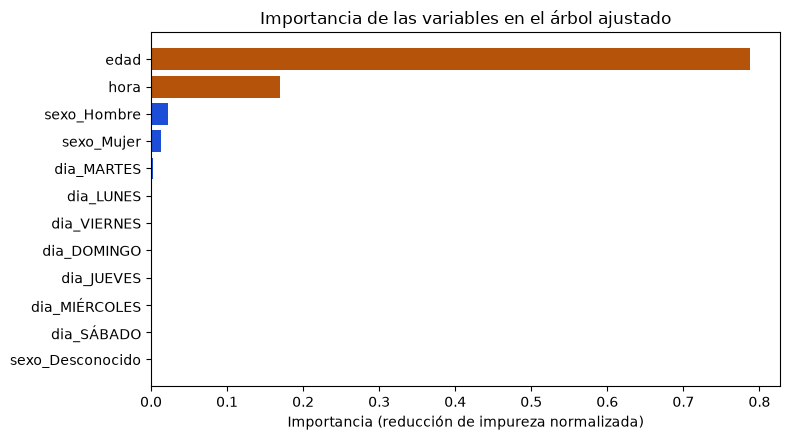

La variable que más usa el árbol es edad (importancia 0.788). La hora queda en 0.170. Sexo y día suman el resto y es poco. Edad y hora no explican la urgencia: el modelo no ve síntomas ni signos vitales, solo el perfil de llegada.


In [4]:
y_proba = modelo.predict_proba(X_test_dm)[:, 1]
# Una sola regla con la sección 5, la logística y Youden: clase 1 si p >= 0,5.
y_pred = (y_proba >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision_no_urgente = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall_no_urgente = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1_no_urgente = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
precision_urgente = precision_score(y_test, y_pred, pos_label=0, zero_division=0)
recall_urgente = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_urgente = f1_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro")

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()

print("Desempeño en prueba, umbral 0,5")
print(f"Accuracy: {porcentaje(accuracy)}")
print(f"Precision de no urgente (clase 1): {porcentaje(precision_no_urgente)}")
print(f"Recall de no urgente (clase 1): {porcentaje(recall_no_urgente)}")
print(f"F1 de no urgente (clase 1): {porcentaje(f1_no_urgente)}")
print(f"Precision de urgente (clase 0): {porcentaje(precision_urgente)}")
print(f"Recall de urgente (clase 0): {porcentaje(recall_urgente)}")
print(f"F1 de urgente (clase 0): {porcentaje(f1_urgente)}")
print(f"F1 macro: {porcentaje(f1_macro)}")
print()
print("Matriz de confusión (filas = triaje real, columnas = predicción)")
print("                 Pred. urgente    Pred. no urgente")
print(f"Real urgente     {tn:12d}    {fp:16d}")
print(f"Real no urgente  {fn:12d}    {tp:16d}")
print()
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Urgente (0)", "No urgente (1)"],
    digits=3,
    zero_division=0,
))
print(
    f"Con el corte 0,5, {miles(fp)} atenciones de triaje 1-3 quedan clasificadas como no urgentes. "
    f"Son el {porcentaje(fp / (tn + fp))} de los {miles(tn + fp)} urgentes de la prueba."
)
print(
    f"En el otro sentido, {miles(fn)} atenciones no urgentes quedan clasificadas como urgentes."
)
print(
    "Cambiar el umbral mueve estos dos conteos. Ningún corte de este cuaderno es clínicamente seguro "
    "y el modelo no decide qué pacientes reciben atención urgente."
)
print(
    f"Accuracy del árbol por defecto en la misma prueba: "
    f"{porcentaje(accuracy_score(y_test, pred_defecto_test))}. "
    f"Accuracy del árbol ajustado: {porcentaje(accuracy)}. "
    f"F1 macro por defecto: {porcentaje(f1_score(y_test, pred_defecto_test, average='macro'))}. "
    f"F1 macro ajustado: {porcentaje(f1_macro)}."
)

importancias = (
    pd.Series(modelo.feature_importances_, index=X_train_dm.columns)
    .sort_values(ascending=False)
)
print()
print("Importancia de variables (suma = 1)")
for nombre, valor in importancias.items():
    if valor > 0:
        print(f"  {nombre}: {valor:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
orden = importancias.sort_values()
colores = ["#b45309" if n in ("edad", "hora") else "#1d4ed8" for n in orden.index]
ax.barh(orden.index, orden.values, color=colores)
ax.set_xlabel("Importancia (reducción de impureza normalizada)")
ax.set_title("Importancia de las variables en el árbol ajustado")
fig.tight_layout()
plt.show()

principal = importancias.index[0]
print(
    f"La variable que más usa el árbol es {principal} "
    f"(importancia {importancias.iloc[0]:.3f}). "
    f"La hora queda en {importancias.get('hora', 0):.3f}. "
    "Sexo y día suman el resto y es poco. "
    "Edad y hora no explican la urgencia: el modelo no ve síntomas ni signos vitales, "
    "solo el perfil de llegada."
)

La importancia queda en la edad y, detrás, en la hora. Sexo y día se ven en el gráfico, pero el peso es bajo. El gráfico no dice que edad y hora expliquen la urgencia. Solo dice cuánto las usa este árbol para separar las dos clases del triaje ya registrado.


## 5. Visualización y uso en el hospital

Las figuras son del árbol ajustado, medidas en la prueba. Esa prueba sale de los 14 hospitales de Castilla y León. No son pacientes del Hospital Obrero N.º 1.

- La curva ROC ordena las probabilidades de no urgente, sin fijar todavía el umbral.
- La matriz cuenta aciertos y errores con la regla de la sección 4 (probabilidad mayor o igual que 0,5).
- El dibujo muestra solo los tres primeros niveles, para poder leerlos. El árbol entrenado es más profundo. El título dice la profundidad real y el número de hojas.

Después de las figuras pruebo los cortes 0,50, 0,60, 0,70 y 0,80 con la misma regla (`>=`). Subir el umbral baja los urgentes clasificados como no urgentes y también clasifica como urgentes a más casos que no lo son. Bajarlo hace lo contrario. En 0,70 siguen quedando urgentes dentro de la clase no urgente. Ningún umbral de la tabla es clínicamente seguro. El modelo no decide qué pacientes reciben atención urgente.


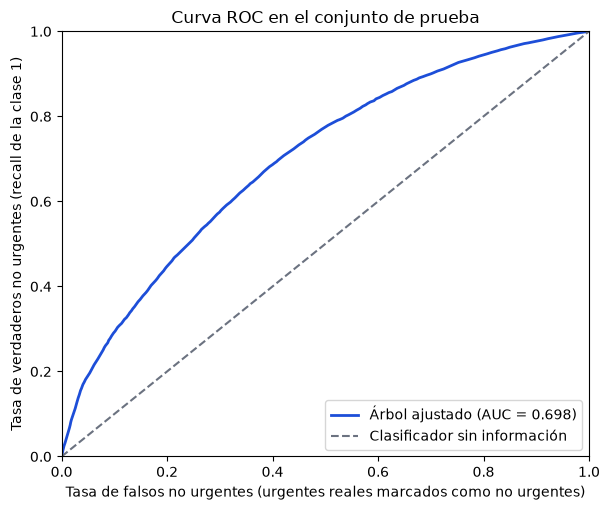

AUC = 0.698. La separación es moderada. Edad, hora, sexo y día ordenan algo el triaje, pero no alcanzan para dar la urgencia por resuelta.
La diagonal es un sistema que no usa las variables. Cuanto más se separa la curva hacia arriba a la izquierda, mejor ordena el árbol a quien el triaje registró como no urgente.


In [5]:
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.plot(fpr, tpr, color="#1d4ed8", linewidth=2, label=f"Árbol ajustado (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="#6b7280", linestyle="--", label="Clasificador sin información")
ax.set_xlabel("Tasa de falsos no urgentes (urgentes reales marcados como no urgentes)")
ax.set_ylabel("Tasa de verdaderos no urgentes (recall de la clase 1)")
ax.set_title("Curva ROC en el conjunto de prueba")
ax.legend(loc="lower right")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

if auc < 0.60:
    lectura_auc = "La separación es débil: edad, hora, sexo y día apenas ordenan el triaje."
elif auc < 0.75:
    lectura_auc = (
        "La separación es moderada. Edad, hora, sexo y día ordenan algo el triaje, "
        "pero no alcanzan para dar la urgencia por resuelta."
    )
else:
    lectura_auc = "La separación es alta para tratarse solo de demografía y calendario."

print(f"AUC = {auc:.3f}. {lectura_auc}")
print(
    "La diagonal es un sistema que no usa las variables. "
    "Cuanto más se separa la curva hacia arriba a la izquierda, mejor ordena "
    "el árbol a quien el triaje registró como no urgente."
)

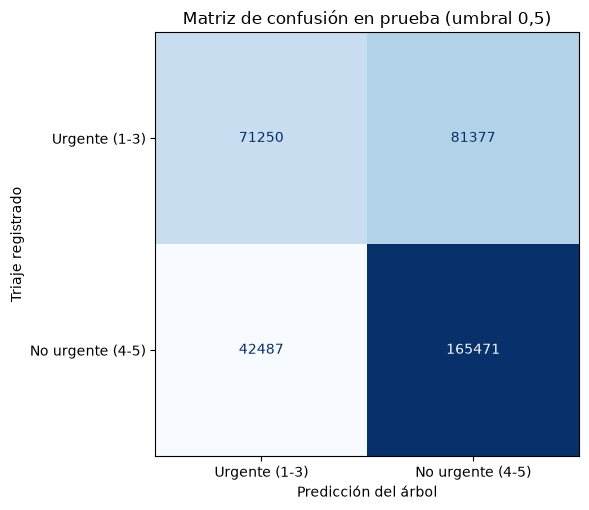

En la prueba, 71.250 urgentes quedan clasificados como urgentes y 165.471 no urgentes quedan como no urgentes. Los 81.377 de la esquina superior derecha son triaje 1-3 clasificado como no urgente. Los 42.487 de la otra esquina son triaje 4-5 clasificado como urgente. Es el mismo corte 0,5 de la sección 4.


In [6]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Urgente (1-3)", "No urgente (4-5)"],
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_xlabel("Predicción del árbol")
ax.set_ylabel("Triaje registrado")
ax.set_title("Matriz de confusión en prueba (umbral 0,5)")
fig.tight_layout()
plt.show()

print(
    f"En la prueba, {miles(tn)} urgentes quedan clasificados como urgentes y {miles(tp)} no urgentes quedan como no urgentes. "
    f"Los {miles(fp)} de la esquina superior derecha son triaje 1-3 clasificado como no urgente. "
    f"Los {miles(fn)} de la otra esquina son triaje 4-5 clasificado como urgente. "
    "Es el mismo corte 0,5 de la sección 4."
)

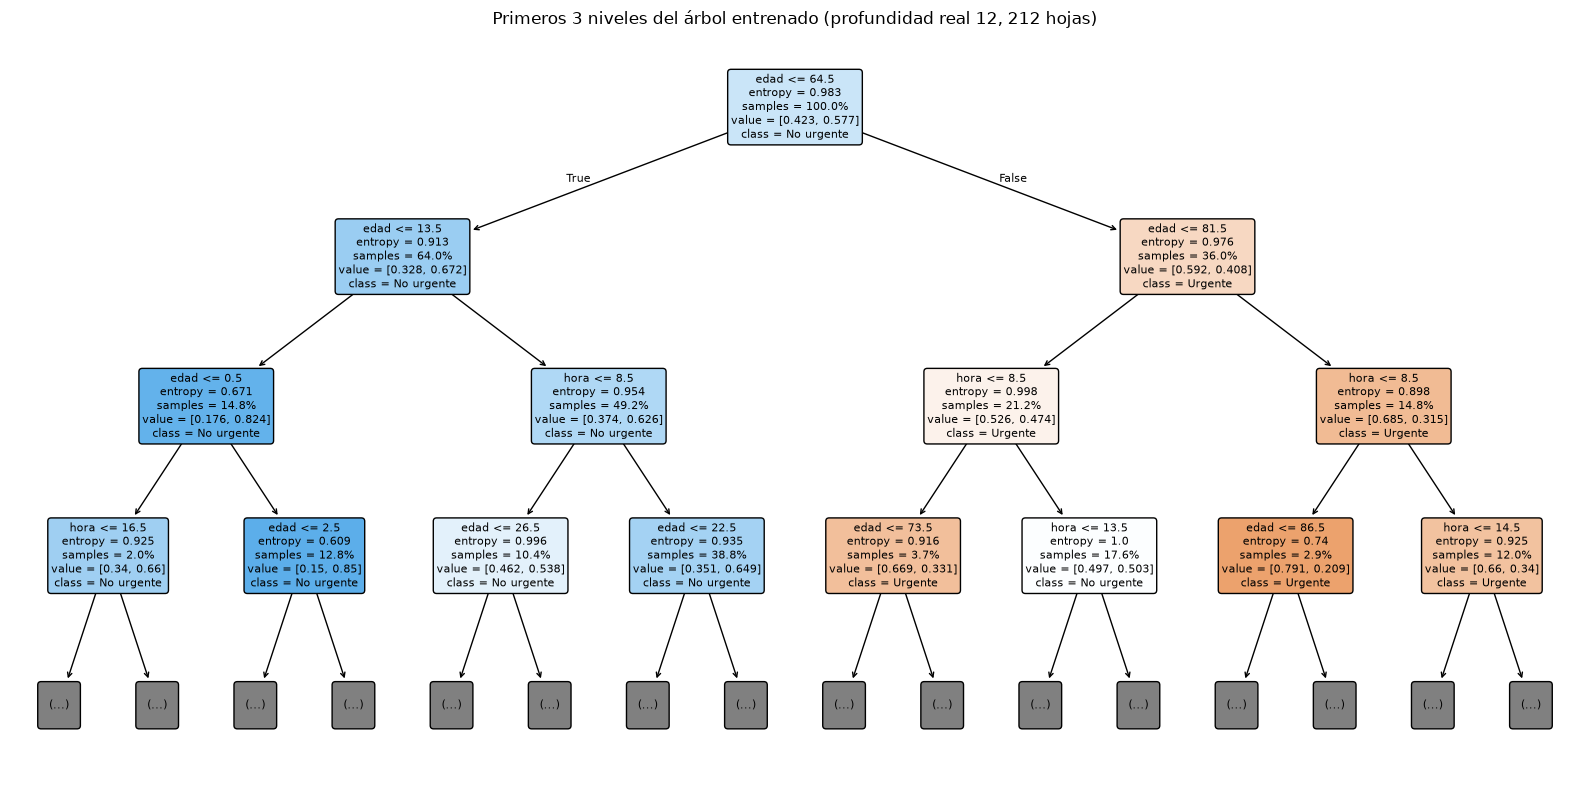

|--- edad <= 64.50
|   |--- edad <= 13.50
|   |   |--- edad <= 0.50
|   |   |   |--- hora <= 16.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- hora >  16.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- edad >  0.50
|   |   |   |--- edad <= 2.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- edad >  2.50
|   |   |   |   |--- truncated branch of depth 8
|   |--- edad >  13.50
|   |   |--- hora <= 8.50
|   |   |   |--- edad <= 26.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- edad >  26.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- hora >  8.50
|   |   |   |--- edad <= 22.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- edad >  22.50
|   |   |   |   |--- truncated branch of depth 9
|--- edad >  64.50
|   |--- edad <= 81.50
|   |   |--- hora <= 8.50
|   |   |   |--- edad <= 73.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- edad >  73.50
|   |   |   | 

In [7]:
profundidad_vista = min(3, modelo.get_depth())
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(
    modelo,
    max_depth=profundidad_vista,
    feature_names=list(X_train_dm.columns),
    class_names=["Urgente", "No urgente"],
    filled=True,
    rounded=True,
    fontsize=8,
    impurity=True,
    proportion=True,
    ax=ax,
)
ax.set_title(
    f"Primeros {profundidad_vista} niveles del árbol entrenado "
    f"(profundidad real {modelo.get_depth()}, {modelo.get_n_leaves()} hojas)"
)
fig.tight_layout()
plt.show()

print(export_text(
    modelo,
    feature_names=list(X_train_dm.columns),
    max_depth=profundidad_vista,
    decimals=2,
    show_weights=True,
))

arbol = modelo.tree_
raiz = 0
variable_raiz = X_train_dm.columns[arbol.feature[raiz]]
umbral_raiz = arbol.threshold[raiz]
hijo_izq = arbol.children_left[raiz]
hijo_der = arbol.children_right[raiz]
nodo_izq_total = arbol.n_node_samples[hijo_izq]
nodo_der_total = arbol.n_node_samples[hijo_der]
prop_izq = arbol.value[hijo_izq][0][1] / arbol.value[hijo_izq][0].sum()
prop_der = arbol.value[hijo_der][0][1] / arbol.value[hijo_der][0].sum()

print(
    f"Lectura de la primera regla, calculada sobre el entrenamiento: "
    f"si {variable_raiz} es menor o igual que {umbral_raiz:.2f}, "
    f"el {porcentaje(prop_izq)} de esas {miles(nodo_izq_total)} filas de entrenamiento "
    f"es no urgente. Si {variable_raiz} es mayor que {umbral_raiz:.2f}, "
    f"la proporción no urgente es {porcentaje(prop_der)} "
    f"({miles(nodo_der_total)} filas). "
    "Los niveles que el gráfico no muestra siguen partiendo esos grupos "
    "con las variables de menor importancia."
)

In [8]:
print("Cortes medidos en la prueba, con la misma regla: no urgente si la probabilidad es mayor o igual que el umbral.")
print(f"{'Umbral':>8} {'Clase 1':>12} {'Precisión clase 1':>20} {'Recall urgente':>16} {'Urgentes en clase 1':>18}")

filas_umbral = []
for umbral in (0.50, 0.60, 0.70, 0.80):
    pred_umbral = (y_proba >= umbral).astype(int)
    enviados = int(pred_umbral.sum())
    precision_via = precision_score(y_test, pred_umbral, pos_label=1, zero_division=0)
    recall_urg = recall_score(y_test, pred_umbral, pos_label=0, zero_division=0)
    colados = int(((y_test == 0) & (pred_umbral == 1)).sum())
    filas_umbral.append((umbral, enviados, precision_via, recall_urg, colados))
    print(
        f"{umbral:8.2f} {porcentaje(enviados / len(y_test)):>12} "
        f"{porcentaje(precision_via):>20} {porcentaje(recall_urg):>16} {miles(colados):>18}"
    )

umbral_propuesto, enviados_p, precision_p, recall_p, colados_p = filas_umbral[2]
_, _, _, _, colados_05 = filas_umbral[0]

print()
print(
    f"Con edad, hora, sexo y día, el AUC es {auc:.3f} y la accuracy "
    f"en el umbral 0,5 es {porcentaje(accuracy)}. El F1 macro del árbol ajustado es "
    f"{porcentaje(f1_macro)}, frente a "
    f"{porcentaje(f1_score(y_test, pred_defecto_test, average='macro'))} "
    f"del árbol por defecto. Los hiperparámetros {busqueda.best_params_} limitan las hojas. "
    "Estas cuatro variables no reproducen el triaje."
)
print(
    f"En el umbral {umbral_propuesto:.2f} quedan {miles(colados_p)} urgentes clasificados como no urgentes "
    f"(en 0,5 eran {miles(colados_05)}). "
    f"Ese corte marca el {porcentaje(enviados_p / len(y_test))} de la prueba como no urgente, "
    f"con precisión {porcentaje(precision_p)}. "
    "Subir el umbral reduce los urgentes que caen en la clase no urgente y aumenta "
    "los no urgentes clasificados como urgentes. "
    "Ningún umbral de la tabla es clínicamente seguro. "
    "El modelo no decide qué pacientes reciben atención urgente. "
    "Las filas son de 14 hospitales de Castilla y León, no del Hospital Obrero N.º 1."
)

Cortes medidos en la prueba, con la misma regla: no urgente si la probabilidad es mayor o igual que el umbral.
  Umbral      Clase 1    Precisión clase 1   Recall urgente Urgentes en clase 1
    0.50      68,46 %              67,03 %          46,68 %             81.377
    0.60      49,32 %              71,54 %          66,84 %             50.606


    0.70      25,41 %              77,90 %          86,74 %             20.243
    0.80      10,83 %              85,29 %          96,24 %              5.742

Con edad, hora, sexo y día, el AUC es 0.698 y la accuracy en el umbral 0,5 es 65,65 %. El F1 macro del árbol ajustado es 63,13 %, frente a 57,11 % del árbol por defecto. Los hiperparámetros {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 200} limitan las hojas. Estas cuatro variables no reproducen el triaje.
En el umbral 0.70 quedan 20.243 urgentes clasificados como no urgentes (en 0,5 eran 81.377). Ese corte marca el 25,41 % de la prueba como no urgente, con precisión 77,90 %. Subir el umbral reduce los urgentes que caen en la clase no urgente y aumenta los no urgentes clasificados como urgentes. Ningún umbral de la tabla es clínicamente seguro. El modelo no decide qué pacientes reciben atención urgente. Las filas son de 14 hospitales de Castilla y León, no del Hospital Obrero N.º 1.


La tabla usa `>=` en los cuatro cortes, el mismo criterio que la matriz de la sección 4. En 0,70 la clase no urgente es más chica y más precisa, y aun así incluye urgentes. El 0,80 también. No hay un corte de esta prueba en el que ese error desaparezca.


## 6. Comparación con la regresión logística

Comparo el árbol ajustado con una regresión logística entrenada en las mismas 64.000 filas y evaluada en la misma prueba. El ajuste es `sm.Logit`, como en el cuaderno de clase, y las probabilidades son las de la clase 1.

La logística lleva intercepto. Para poder estimarlo dejo fuera una categoría de sexo (`sexo_Mujer`) y una de día (`dia_LUNES`). El árbol sigue usando todas las indicadoras. Las filas no cambian.

Los dos modelos se cortan con la misma regla del árbol: clase 1 si la probabilidad es mayor o igual que 0,5. Así el conteo de urgentes clasificados como no urgentes puede compararse con la sección 4. Reporto exactitud, sensibilidad (recall de no urgente), precisión y F1, y también ese conteo.


In [9]:
import statsmodels.api as sm

referencia = ["sexo_Mujer", "dia_LUNES"]
columnas_logit = [c for c in X_train_dm.columns if c not in referencia]
X_train_logit = sm.add_constant(
    X_train_dm[columnas_logit].reset_index(drop=True),
    has_constant="add",
)
X_test_logit = sm.add_constant(
    X_test_dm[columnas_logit].reset_index(drop=True),
    has_constant="add",
)
X_test_logit = X_test_logit.reindex(columns=X_train_logit.columns, fill_value=0.0)
y_train_logit = y_train.reset_index(drop=True).astype(float)
y_test_cmp = y_test.reset_index(drop=True).astype(int)

modelo_logit = sm.Logit(y_train_logit, X_train_logit).fit(disp=False, maxiter=100)
y_pred_logit = modelo_logit.predict(X_test_logit)
y_pred_ArbolDecisionClasif = pd.Series(np.asarray(y_proba), index=y_test_cmp.index)

print("Regresión logística (sm.Logit) en la misma partición")
print(f"Convergió: {modelo_logit.mle_retvals.get('converged')}")
print(f"Pseudo R²: {modelo_logit.prsquared:.4f}")
print("Referencia de las categóricas: sexo Mujer y día lunes.")
print("Coeficientes de las variables numéricas (log-odds de no urgente):")
print(modelo_logit.params[["const", "edad", "hora"]].round(4).to_string())
print(
    "El coeficiente de edad es negativo: a más edad, menor log-odds de triaje 4-5. "
    "Coincide con la primera rama del árbol, que separa en 64,5 años y deja "
    "menos proporción de no urgentes por encima de ese corte. "
    "El coeficiente de hora es positivo: más tarde en el día, más log-odds de baja complejidad."
)

def metricas_corte(y_real, probabilidad, umbral):
    pred = (np.asarray(probabilidad) >= umbral).astype(int)
    y_real = np.asarray(y_real)
    matriz = confusion_matrix(y_real, pred, labels=[0, 1])
    tn, fp, fn, tp = matriz.ravel()
    return {
        "accuracy": accuracy_score(y_real, pred),
        "sensibilidad": recall_score(y_real, pred, pos_label=1, zero_division=0),
        "precision": precision_score(y_real, pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_real, pred, pos_label=1, zero_division=0),
        "recall_urgente": recall_score(y_real, pred, pos_label=0, zero_division=0),
        "criticos": int(fp),
        "matriz": matriz,
    }

def imprimir_metricas(titulo, m):
    print(titulo)
    print(f"  Exactitud: {porcentaje(m['accuracy'])}")
    print(f"  Sensibilidad (recall de no urgente): {porcentaje(m['sensibilidad'])}")
    print(f"  Precisión de no urgente: {porcentaje(m['precision'])}")
    print(f"  F1 de no urgente: {porcentaje(m['f1'])}")
    print(f"  Recall de urgente: {porcentaje(m['recall_urgente'])}")
    print(f"  Urgentes marcados como no urgentes: {miles(m['criticos'])}")
    print("  Matriz [[VN, FP], [FN, VP]]:")
    print(m["matriz"])

logit_05 = metricas_corte(y_test_cmp, y_pred_logit, 0.5)
arbol_05 = metricas_corte(y_test_cmp, y_pred_ArbolDecisionClasif, 0.5)

print()
imprimir_metricas("Logit en el umbral 0,5", logit_05)
print()
imprimir_metricas("Árbol ajustado en el umbral 0,5", arbol_05)

auc_logit = roc_auc_score(y_test_cmp, y_pred_logit)
auc_arbol = roc_auc_score(y_test_cmp, y_pred_ArbolDecisionClasif)
print(
    f"Urgentes clasificados como no urgentes con el árbol y la regla >= 0,5: "
    f"{miles(arbol_05['criticos'])}. En la sección 4, con la misma regla, son {miles(fp)}."
)
print()
print(f"AUC logit: {auc_logit:.3f}")
print(f"AUC árbol: {auc_arbol:.3f}")
if auc_arbol >= auc_logit:
    mejor_orden = "el árbol ordena un poco mejor las llegadas"
else:
    mejor_orden = "la logística ordena un poco mejor las llegadas"
print(
    f"En el mismo corte de 0,5, {mejor_orden} "
    f"(AUC {auc_arbol:.3f} frente a {auc_logit:.3f}). "
    f"La exactitud del árbol es {porcentaje(arbol_05['accuracy'])} y la del logit "
    f"{porcentaje(logit_05['accuracy'])}. "
    f"El F1 de no urgente es {porcentaje(arbol_05['f1'])} en el árbol y "
    f"{porcentaje(logit_05['f1'])} en el logit. "
    f"Los urgentes clasificados como no urgentes son {miles(arbol_05['criticos'])} con el árbol y "
    f"{miles(logit_05['criticos'])} con el logit. "
    "La diferencia es pequeña. Edad y hora son las variables que más usa el árbol; "
    "sexo y día aportan poco, y no hay síntomas ni signos vitales en el modelo."
)

Regresión logística (sm.Logit) en la misma partición
Convergió: True
Pseudo R²: 0.0702
Referencia de las categóricas: sexo Mujer y día lunes.
Coeficientes de las variables numéricas (log-odds de no urgente):
const    1.4177
edad    -0.0234
hora     0.0120
El coeficiente de edad es negativo: a más edad, menor log-odds de triaje 4-5. Coincide con la primera rama del árbol, que separa en 64,5 años y deja menos proporción de no urgentes por encima de ese corte. El coeficiente de hora es positivo: más tarde en el día, más log-odds de baja complejidad.



Logit en el umbral 0,5
  Exactitud: 64,16 %
  Sensibilidad (recall de no urgente): 74,23 %
  Precisión de no urgente: 67,12 %
  F1 de no urgente: 70,49 %
  Recall de urgente: 50,45 %
  Urgentes marcados como no urgentes: 75.633
  Matriz [[VN, FP], [FN, VP]]:
[[ 76994  75633]
 [ 53588 154370]]

Árbol ajustado en el umbral 0,5
  Exactitud: 65,65 %
  Sensibilidad (recall de no urgente): 79,57 %
  Precisión de no urgente: 67,03 %
  F1 de no urgente: 72,77 %
  Recall de urgente: 46,68 %
  Urgentes marcados como no urgentes: 81.377
  Matriz [[VN, FP], [FN, VP]]:
[[ 71250  81377]
 [ 42487 165471]]
Urgentes clasificados como no urgentes con el árbol y la regla >= 0,5: 81.377. En la sección 4, con la misma regla, son 81.377.

AUC logit: 0.676
AUC árbol: 0.698
En el mismo corte de 0,5, el árbol ordena un poco mejor las llegadas (AUC 0.698 frente a 0.676). La exactitud del árbol es 65,65 % y la del logit 64,16 %. El F1 de no urgente es 72,77 % en el árbol y 70,49 % en el logit. Los urgentes clas

En el corte 0,5 los dos modelos quedan cerca. El árbol tiene un AUC un poco mayor. Edad entra con coeficiente negativo en el logit (a más edad, menos log-odds de triaje 4-5) y la hora entra con coeficiente positivo. Eso va en la misma dirección que la primera rama del árbol, que parte por edad. No es una explicación de la urgencia: faltan síntomas y signos vitales.


## 7. Umbral de Youden

El índice de Youden en un punto de la curva ROC es la sensibilidad menos la tasa de falsos positivos (`tpr - fpr`). El umbral de Youden es el corte donde ese índice es máximo. Lo calculo para el logit y para el árbol, sobre la misma prueba, como en el cuaderno de clase.

Ese umbral sale de la prueba que después mido. Sirve para ver el corte dentro de este ejercicio. No es un umbral validado aparte.

Abajo comparo las métricas de Youden con las del corte 0,5. Youden reparte el mismo peso a los dos errores. En la tabla anterior, el corte 0,70 sigue dejando urgentes dentro de la clase no urgente. Mover el umbral cambia el equilibrio. No lo vuelve clínicamente seguro, y el modelo no decide la atención.


In [10]:
def umbral_youden(y_real, probabilidad):
    fpr, tpr, thresholds = roc_curve(y_real, probabilidad)
    youden_index = tpr - fpr
    finitos = np.isfinite(thresholds)
    posicion = np.flatnonzero(finitos)[np.argmax(youden_index[finitos])]
    return float(thresholds[posicion]), float(youden_index[posicion]), fpr, tpr

optimal_threshold_logit, youden_logit, fpr_logit, tpr_logit = umbral_youden(
    y_test_cmp, y_pred_logit
)
optimal_threshold_tree, youden_tree, fpr_tree, tpr_tree = umbral_youden(
    y_test_cmp, y_pred_ArbolDecisionClasif
)

print("Umbral óptimo Logit:", optimal_threshold_logit)
print("Índice de Youden del logit:", round(youden_logit, 4))
print("Umbral óptimo - Árbol de decisión:", optimal_threshold_tree)
print("Índice de Youden del árbol:", round(youden_tree, 4))

logit_youden = metricas_corte(y_test_cmp, y_pred_logit, optimal_threshold_logit)
arbol_youden = metricas_corte(y_test_cmp, y_pred_ArbolDecisionClasif, optimal_threshold_tree)

print()
imprimir_metricas(
    f"Logit en el umbral de Youden ({optimal_threshold_logit:.4f})",
    logit_youden,
)
print()
imprimir_metricas(
    f"Árbol en el umbral de Youden ({optimal_threshold_tree:.4f})",
    arbol_youden,
)

print()
print("Matriz de confusión - Logit (Youden):")
print(confusion_matrix(
    y_test_cmp,
    (np.asarray(y_pred_logit) >= optimal_threshold_logit).astype(int),
    labels=[0, 1],
))
print("Matriz de confusión - Árbol de decisión (Youden):")
print(confusion_matrix(
    y_test_cmp,
    (np.asarray(y_pred_ArbolDecisionClasif) >= optimal_threshold_tree).astype(int),
    labels=[0, 1],
))

def frase_cambio(nombre, base, nuevo, umbral):
    return (
        f"{nombre}: el corte pasa de 0,5 a {umbral:.4f}. "
        f"La exactitud pasa de {porcentaje(base['accuracy'])} a {porcentaje(nuevo['accuracy'])}. "
        f"La sensibilidad de no urgente pasa de {porcentaje(base['sensibilidad'])} a {porcentaje(nuevo['sensibilidad'])}. "
        f"La precisión pasa de {porcentaje(base['precision'])} a {porcentaje(nuevo['precision'])}. "
        f"El F1 pasa de {porcentaje(base['f1'])} a {porcentaje(nuevo['f1'])}. "
        f"El recall de urgente pasa de {porcentaje(base['recall_urgente'])} a {porcentaje(nuevo['recall_urgente'])}. "
        f"Los urgentes marcados como no urgentes pasan de {miles(base['criticos'])} a {miles(nuevo['criticos'])}."
    )

print()
print(frase_cambio("Logit", logit_05, logit_youden, optimal_threshold_logit))
print(frase_cambio("Árbol", arbol_05, arbol_youden, optimal_threshold_tree))
print(
    "Youden da el mismo peso a los dos errores. "
    "En 0,70 siguen quedando urgentes clasificados como no urgentes. "
    "Pasar de 0,5 a Youden o a 0,70 solo mueve ese equilibrio. "
    "Ninguno de estos cortes es clínicamente seguro y el modelo no decide qué pacientes reciben atención urgente."
)

Umbral óptimo Logit: 0.5309589791306163
Índice de Youden del logit: 0.2526
Umbral óptimo - Árbol de decisión: 0.5633802816901409
Índice de Youden del árbol: 0.2875



Logit en el umbral de Youden (0.5310)
  Exactitud: 63,49 %
  Sensibilidad (recall de no urgente): 68,22 %
  Precisión de no urgente: 68,39 %
  F1 de no urgente: 68,30 %
  Recall de urgente: 57,04 %
  Urgentes marcados como no urgentes: 65.572
  Matriz [[VN, FP], [FN, VP]]:
[[ 87055  65572]
 [ 66091 141867]]

Árbol en el umbral de Youden (0.5634)
  Exactitud: 64,96 %
  Sensibilidad (recall de no urgente): 68,17 %
  Precisión de no urgente: 70,20 %
  F1 de no urgente: 69,17 %
  Recall de urgente: 60,58 %
  Urgentes marcados como no urgentes: 60.170
  Matriz [[VN, FP], [FN, VP]]:
[[ 92457  60170]
 [ 66195 141763]]

Matriz de confusión - Logit (Youden):
[[ 87055  65572]
 [ 66091 141867]]
Matriz de confusión - Árbol de decisión (Youden):
[[ 92457  60170]
 [ 66195 141763]]

Logit: el corte pasa de 0,5 a 0.5310. La exactitud pasa de 64,16 % a 63,49 %. La sensibilidad de no urgente pasa de 74,23 % a 68,22 %. La precisión pasa de 67,12 % a 68,39 %. El F1 pasa de 70,49 % a 68,30 %. El recall de

Con Youden el corte del árbol queda por encima de 0,5 y el del logit también, pero los dos siguen cerca de 0,5. La exactitud y el F1 no suben. Lo que baja es el número de urgentes clasificados como no urgentes, y lo que sube es el de no urgentes clasificados como urgentes. El umbral se eligió en la misma prueba, así que no es un resultado aparte.


## Conclusiones

El objetivo era clasificar el triaje urgente (1-3) frente al no urgente (4-5) con edad, hora, sexo y día de la semana.

En la prueba, el árbol ajustado (entropía, profundidad 12, `min_samples_leaf` 200) queda por encima del árbol por defecto en F1 macro. El árbol por defecto se sobreajusta. Frente a la logística, en la misma partición y con el mismo corte 0,5, el AUC del árbol es un poco mayor. La diferencia entre los dos modelos es pequeña.

La edad concentra la importancia y la hora va después. Sexo y día casi no entran. Esas cuatro variables no incluyen síntomas ni signos vitales, así que no explican la urgencia.

Limitaciones de este ejercicio: los registros son de 14 hospitales de Castilla y León, no del Hospital Obrero N.º 1; el ajuste usa 64.000 filas del entrenamiento, no todo el entrenamiento; el umbral de Youden se calcula en la misma prueba que se evalúa; en 0,5, en Youden y en 0,70 siguen apareciendo urgentes clasificados como no urgentes. Cambiar el umbral mueve ese equilibrio. Ningún corte de aquí es clínicamente seguro y el modelo no decide la atención.
